# Session 21 Solutions: Measuring Model Performance

Data Science with Python, Level 1, Stage 3: Statistics and ML Fundamentals

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             classification_report, roc_curve, roc_auc_score,
                             mean_absolute_error, root_mean_squared_error, r2_score)

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"

churn = pd.read_csv(DATA_URL + "telecom_churn.csv")
churn["left"] = (churn["churn"] == "Yes").astype(int)
churn["monthly_contract"] = (churn["contract"] == "Month-to-month").astype(int)
churn["fiber"] = (churn["internet"] == "Fiber").astype(int)
churn["echeck"] = (churn["payment_method"] == "Electronic check").astype(int)
features = ["tenure_months", "monthly_charges", "support_calls", "senior",
            "monthly_contract", "fiber", "echeck"]
X_train, X_test, y_train, y_test = train_test_split(
    churn[features].astype(float), churn["left"],
    test_size=0.25, random_state=42, stratify=churn["left"])
scaler = StandardScaler().fit(X_train)
model = LogisticRegression().fit(scaler.transform(X_train), y_train)
pred = model.predict(scaler.transform(X_test))
proba = model.predict_proba(scaler.transform(X_test))[:, 1]

## In-Class Exercises

### In-Class Exercise 1: Metrics by Hand

In [2]:
tn, fp, fn, tp = 308, 41, 93, 58
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)
print(round(precision, 3), round(recall, 3), round(f1, 3))

0.586 0.384 0.464


### In-Class Exercise 2: Best F1 Threshold

In [3]:
best = max(np.arange(0.10, 0.91, 0.05), key=lambda t: f1_score(y_test, (proba >= t).astype(int)))
print(round(best, 2), round(f1_score(y_test, (proba >= best).astype(int)), 3))

0.3 0.674


### In-Class Exercise 3: Which Metric?

In [4]:
answers = {
    "cancer screening": "recall: a missed cancer is far worse than an extra check",
    "blocking payments": "precision: blocking a real customer is costly",
    "delivery minutes": "MAE: easy to explain in minutes",
    "call list ranking": "ROC AUC: we care about the order, not one threshold",
}
for case, a in answers.items():
    print(case, "->", a)

cancer screening -> recall: a missed cancer is far worse than an extra check
blocking payments -> precision: blocking a real customer is costly
delivery minutes -> MAE: easy to explain in minutes
call list ranking -> ROC AUC: we care about the order, not one threshold


### In-Class Exercise 4: Errors by Price

In [5]:
flats = pd.read_csv(DATA_URL + "apartments.csv")
cols = ["area_m2", "rooms", "building_age", "distance_center_km", "elevator", "parking"]
Xa_train, Xa_test, ya_train, ya_test = train_test_split(flats[cols].astype(float), flats["price_k"], test_size=0.25, random_state=42)
reg = LinearRegression().fit(Xa_train, ya_train)
res = flats.loc[Xa_test.index, ["district", "area_m2", "price_k"]].assign(predicted=reg.predict(Xa_test).round(1))
res["error"] = (res["price_k"] - res["predicted"]).abs()
res.nlargest(5, "error")

,district,area_m2,price_k,predicted,error
350,Hillview,110,328.4,116.9,211.5
719,Westpark,115,202.2,74.5,127.7
54,Westpark,68,137.5,50.3,87.2
148,Old Town,119,178.0,139.2,38.8
787,Riverside,35,52.5,86.6,34.1


## Part A: Basic

### Exercise 1: A Tiny Example

In [6]:
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 0, 1]
y_hat = [1, 0, 0, 1, 0, 1, 1, 0, 0, 0]
print(confusion_matrix(y_true, y_hat))
print(precision_score(y_true, y_hat), recall_score(y_true, y_hat), round(f1_score(y_true, y_hat), 3))

[[4 1]
 [2 3]]
0.75 0.6 0.667


### Exercise 2: MAE and RMSE by Hand

In [7]:
real = np.array([30, 25, 40, 35, 50])
guess = np.array([28, 27, 38, 36, 30])
err = real - guess
print(np.abs(err).mean(), np.sqrt((err ** 2).mean()).round(2))
print(mean_absolute_error(real, guess), round(root_mean_squared_error(real, guess), 2))
# One prediction is 20 minutes off; squaring makes that error dominate.

5.4 9.09
5.4 9.09


## Part B: Intermediate

### Exercise 3: Breast Cancer Classifier

In [8]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer(as_frame=True)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(data.data, data.target, test_size=0.25, random_state=0, stratify=data.target)
sc = StandardScaler().fit(Xb_train)
m = LogisticRegression(max_iter=1000).fit(sc.transform(Xb_train), yb_train)
print(classification_report(yb_test, m.predict(sc.transform(Xb_test)), target_names=data.target_names))
print(round(roc_auc_score(yb_test, m.predict_proba(sc.transform(Xb_test))[:, 1]), 4))
# Recall for malignant: missing a cancer is the worst mistake.

              precision    recall  f1-score   support

   malignant       0.94      0.94      0.94        53
      benign       0.97      0.97      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.96      0.96       143
weighted avg       0.96      0.96      0.96       143

0.9952


### Exercise 4: Precision-Recall Chart

`zero_division=0` avoids a warning at high thresholds where the model flags nobody.

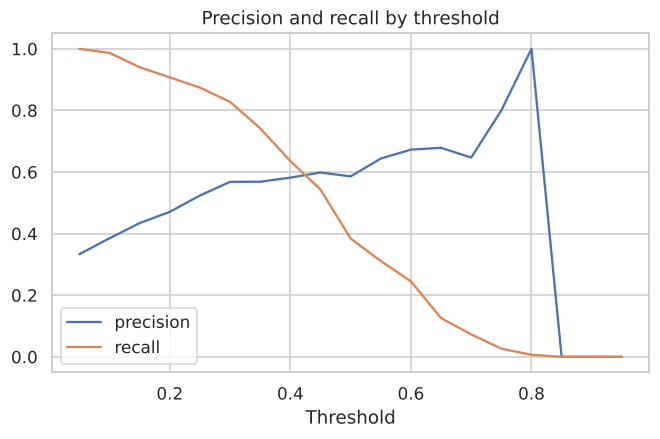

In [9]:
ts = np.arange(0.05, 0.96, 0.05)
prec = [precision_score(y_test, (proba >= t).astype(int), zero_division=0) for t in ts]
rec = [recall_score(y_test, (proba >= t).astype(int)) for t in ts]
plt.plot(ts, prec, label="precision")
plt.plot(ts, rec, label="recall")
plt.xlabel("Threshold")
plt.legend()
plt.title("Precision and recall by threshold")
plt.show()

## Part C: Challenge

### Exercise 5: Fraud: Accuracy versus Recall

In [10]:
from sklearn.metrics import accuracy_score
tx = pd.read_csv(DATA_URL + "card_transactions.csv")
cols = ["amount", "hour", "distance_from_home_km", "online", "new_merchant"]
Xf_train, Xf_test, yf_train, yf_test = train_test_split(tx[cols].astype(float), tx["is_fraud"], test_size=0.25, random_state=1, stratify=tx["is_fraud"])
sc = StandardScaler().fit(Xf_train)
m = LogisticRegression().fit(sc.transform(Xf_train), yf_train)
pf = m.predict_proba(sc.transform(Xf_test))[:, 1]
p = (pf >= 0.5).astype(int)
print(round(accuracy_score(yf_test, p), 4), precision_score(yf_test, p, zero_division=0), recall_score(yf_test, p), round(roc_auc_score(yf_test, pf), 3))
for t in np.arange(0.5, 0.0, -0.01):
    p = (pf >= t).astype(int)
    if recall_score(yf_test, p) >= 0.8:
        print("threshold", round(t, 2), "precision", round(precision_score(yf_test, p), 3))
        break

0.998 0.9285714285714286 0.9629629629629629 1.0
threshold 0.5 precision 0.929


## Part D: Cumulative Project: Apartment Prices

### Exercise 6: Apartment Prices: Report Card

In [11]:
def report(model, X_train, X_test, y_train, y_test):
    pred = model.fit(X_train, y_train).predict(X_test)
    base = np.full(len(y_test), y_train.mean())
    for name, p in [("model", pred), ("baseline", base)]:
        print(f"{name:9} MAE {mean_absolute_error(y_test, p):6.1f}  RMSE {root_mean_squared_error(y_test, p):6.1f}  R2 {r2_score(y_test, p):6.3f}")

flats = pd.read_csv(DATA_URL + "apartments.csv")
cols = ["area_m2", "rooms", "building_age", "distance_center_km", "elevator", "parking"]
Xa_train, Xa_test, ya_train, ya_test = train_test_split(flats[cols].astype(float), flats["price_k"], test_size=0.25, random_state=42)
report(LinearRegression(), Xa_train[["area_m2"]], Xa_test[["area_m2"]], ya_train, ya_test)
report(LinearRegression(), Xa_train, Xa_test, ya_train, ya_test)

model     MAE   23.2  RMSE   31.6  R2  0.419
baseline  MAE   32.0  RMSE   41.6  R2 -0.004
model     MAE   11.7  RMSE   22.3  R2  0.711
baseline  MAE   32.0  RMSE   41.6  R2 -0.004


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | Recall = TP / (TP + FN). |
| 2 | B | False positives are the costly error. |
| 3 | B | The ROC curve lies on the diagonal. |
| 4 | B | Squaring gives big errors more weight. |
| 5 | B | R2 compares the model with the mean baseline. |